In [2]:
from langchain_openai import ChatOpenAI
from dotenv import load_dotenv
from langchain_core.prompts import PromptTemplate
from langchain_core.output_parsers  import StrOutputParser

load_dotenv()

True

## TABLE OF CONTENTS 

 1)  simple chain 
 2)  sequential chain 
 3)  spatial drawing (example)  

 contents further are 
 1)  parallel chains 
 2)  conditional chains 



 ### Theory part 
 In short: Chains were LangChain’s original way to connect steps. Each chain was its own class with its own API. Runnables replaced them with one standard interface that every component implements. Today, a “chain” just means several Runnables joined with the | operator. This style is called LCEL (LangChain Expression Language).

 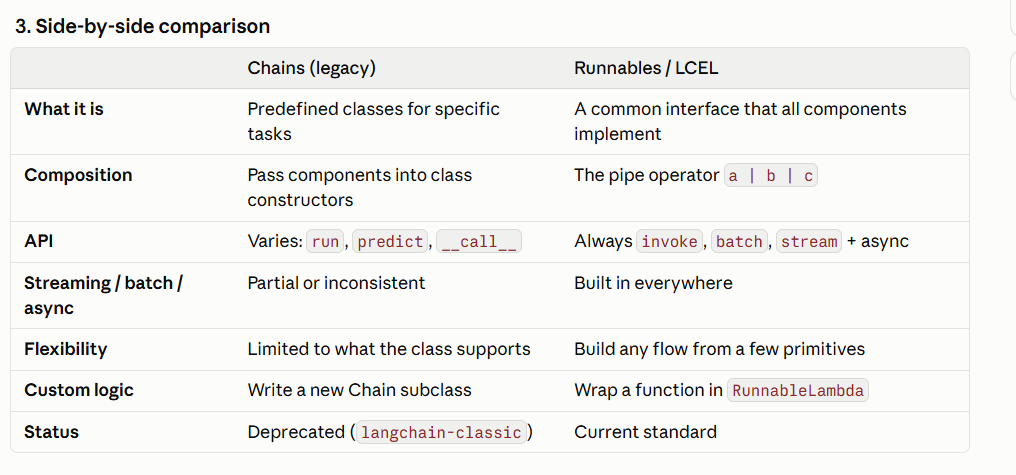

## 1)  simple chain 

In [5]:
# one prompt and one LLM models based 
# input → prompt → LLM → output

prompt =  PromptTemplate(
    template = "Give major pros and cons of {var}",
    input_variables=["var"]
    
)


model  = ChatOpenAI()
parser = StrOutputParser()


chain  =  prompt |  model | parser 
result =  chain.invoke({"var" : "visiting  india  ?  "})

print(result)


chain.get_graph().print_ascii()

Major pros of visiting India:
1. Rich cultural heritage: India is home to diverse cultures, traditions, and architectural marvels that offer a unique and enriching experience for visitors.
2. Delicious cuisine: Indian cuisine is known for its vast array of flavors and spices, offering a gastronomic adventure for food enthusiasts.
3. Stunning natural landscapes: From the lush green forests of Kerala to the snow-capped mountains of the Himalayas, India boasts a wide range of breathtaking natural landscapes.
4. Affordable travel: India is known for its budget-friendly travel options, making it an ideal destination for budget-conscious travelers.
5. Spiritual retreats: India is home to numerous spiritual and meditation retreats that offer a peaceful and serene atmosphere for self-reflection and rejuvenation.

Major cons of visiting India:
1. Overcrowding: Many popular tourist destinations in India can be overcrowded, making it difficult to fully enjoy the experience.
2. Sanitation issues: 

## 2) Sequential chain 

In [6]:
p1 =  PromptTemplate(
    template="write the paragraph about {topic}",
    input_variables=["topic"]
    
)


p2 = PromptTemplate(
    template="generate 5 quiz questions on the {para}",
    input_variables=["para"]
)


model  =  ChatOpenAI()

parser =  StrOutputParser()


chain1 =  p1 |  model |  parser

chain2 =  p2 |  model |  parser 


# A simple sequential chain to generate the desired topic by the user and then generate five questions on the paragraphs generated 

while True : 
    
    topic_name =  input("Enter the topic of physics you want to study ? ")
    
    
    if topic_name in  ["exit","quit","Q"]:
        break 
        
    
    result  =  chain1.invoke({"topic":topic_name}) # < - Generating the desired paragraph of the user 
    
    print(result)
    
    quiz = chain2.invoke({"para":result}) # < - Generating the quizzes based on the paragraph 
    print(quiz)
    
    
    


chain1.get_graph().print_ascii()
chain2.get_graph().print_ascii()
    
    
    
    
        
    
    
    
    
    

Schrödinger's wave equation is a fundamental equation in quantum mechanics that describes the behavior of particles at the microscopic level. This equation is used to calculate the probability of finding a particle in a certain position or state. The wave function in this equation represents the probability amplitude of the particle, and it evolves over time according to the equation. This equation is crucial in predicting the behavior of electrons in atoms, as well as other subatomic particles. The wave function can be used to determine the probability distribution of a particle's position, momentum, and energy. Schrödinger's wave equation forms the foundation of quantum mechanics and has led to many groundbreaking discoveries in the field of particle physics.
1. What is the Schrödinger's wave equation used to calculate in quantum mechanics?
2. How does the wave function in the Schrödinger's wave equation represent the behavior of particles at the microscopic level?
3. How does the Sc

## 3)  Spatial Drawing by genAI 

In [7]:
template  = """


System  : you are a A S C I I pencil artist And you have to draw a spatial drawing with only two characters: * and #. 
          We don't need any explanation text, just the spatial drawing. 
          
          
Human :  girl 
AI  :              ######
          ############
        ######****######
       ####**********####
      ####**##****##**####
      ####************####
      ####*****##*****####
      #####**********#####
      ######********######
     #######   ****   #######
     ######  ********  ######
     ####   **********   ####
    ###    ************    ###
   ##     **************     ##
         ****************
        ******************
       ********************
      **********************
             #        #
             #        #
            ##        ##
            
            
Now, similarly, when the user enters the topic, you have to draw this kind of drawing for the {topic}



"""



p1 =  PromptTemplate(
    template=template,
    input_variables=["topic"]
    
)

model =  ChatOpenAI(model = "gpt-6-luna")
parser = StrOutputParser()


chain  =  p1 |  model  | parser 


print(chain.invoke({"solar system"}))

                         #
              *****************
          ****                 ****
       ***                         ***
     **       *****************       **
    **     ***               ***       **
   **    **       *********     **       **
  **   **      **         **     **   #   **
  *   **      *      ###    *      **      *
  **   **      *     #####   *      **      **
   **   **      **   ##### **      **   #  **
    **   **      ***   #  ***     **   **
      **  ***      *********    ***  **
        ***   ***             ***  ***
            *****************
